# A9 · Opening up the model, part 1: why does it say what it says?

**Where we are**

```
A6–A7  trained the model (LightGBM)   →   A8  tested it once on Jul–Aug: 86% on time at P75
A9     HERE, part 1: why does it say what it says?   (part 2: is it fair to every group?  part 3: tuning + model card)
```

**The one idea:** every prediction is **a starting point plus one push per column**.

- **Starting point:** the model's average prediction, the same number for every visit.
- **Push:** how many minutes one column moves *this* visit's prediction, up (+) or down (−).
- The pushes **add up exactly** to the prediction. These pushes are called **SHAP values**; LightGBM computes them itself with `predict(X, pred_contrib=True)`.

**Why we can do something real projects can't:** we wrote the simulator (A2), so we know the true rule. We can check whether a push the model found matches the push the rule says it should be.

We explain the **final P80 model** from A8 (trained on January–June) on the **July–August test visits**. Explaining doesn't choose anything, so looking at the test months here is fine.

In [1]:
%load_ext autoreload
%autoreload 2

import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from slotpred import explain as ex
from slotpred.config import ROOT

booster = ex.final_model(0.8)          # the final P80 model from A8
X, visits = ex.test_table()            # Jul-Aug: the model's columns, and the visits with the simulator's answer key
print(X.shape, "columns:", list(X.columns))

(11664, 10) columns: ['department', 'visit_type', 'doctor', 'clinic', 'age', 'age_missing', 'teleconsult', 'prior_reports', 'weekday', 'hour']


## 1 · Split every prediction into pushes

**TODO(you):** write `pushes(booster, X)` in [slotpred/explain.py](../slotpred/explain.py). It's about three lines: call `booster.predict(X, pred_contrib=True)` and put the result in a DataFrame with the right column names and index. The docstring says exactly what to return. Then run the tests below.

In [2]:
!"{sys.executable}" -m pytest "{ROOT / 'tests' / 'test_explain.py'}" -q -k pushes

..                                                                       [100%]
2 passed, 4 deselected in 1.79s


In [4]:
P = ex.pushes(booster, X)
print("starting point:", round(P["start"].iloc[0], 2), "min")
print("largest gap between (sum of pushes) and the prediction:", np.abs(P.sum(axis=1).to_numpy() - np.asarray(booster.predict(X), dtype=float)).max())

starting point: 15.68 min
largest gap between (sum of pushes) and the prediction: 1.1368683772161603e-13


## 2 · One visit, column by column

Dr Deepak Rao, **follow-up by video**, HSR, age 46, no prior reports, Tuesday 15:45.

In [5]:
i = visits.index[(visits.doctor == "Deepak Rao") & (visits.visit_type == "follow-up") & (visits.teleconsult == 1)
                 & (visits.clinic == "HSR") & (visits.age == 46)][0]
row = P.loc[i].drop("start").sort_values(key=abs, ascending=False)
print(f"start {P.loc[i, 'start']:.1f}")
for col, push in row.items():
    print(f"  {col:14s} {push:+.2f}")
print(f"= P80 {booster.predict(X.loc[[i]])[0]:.2f} min   (actual: {visits.loc[i, 'minutes']:.1f} min)")

start 15.7
  visit_type     -3.56
  doctor         -2.80
  teleconsult    -1.53
  prior_reports  -1.18
  clinic         +0.26
  age            -0.18
  weekday        -0.08
  hour           +0.06
  department     -0.06
  age_missing    +0.00
= P80 6.61 min   (actual: 4.2 min)


## 3 · Which columns matter, on average?

Average the *size* of each column's push over all test visits (ignoring up or down).

visit_type       4.61
doctor           3.08
prior_reports    1.19
age              0.42
clinic           0.42
hour             0.39
weekday          0.29
teleconsult      0.17
department       0.12
age_missing      0.00
dtype: float64


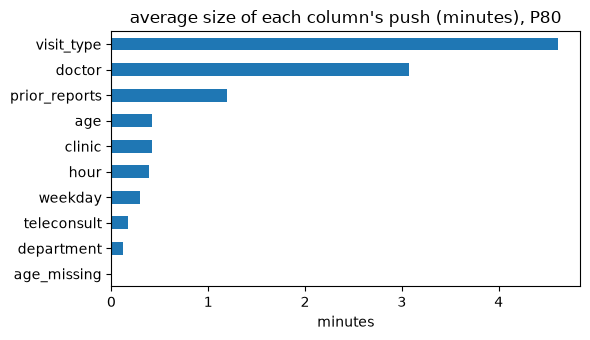

In [6]:
avg = ex.average_push(P)
print(avg.round(2))
avg[::-1].plot.barh(figsize=(6, 3.5), title="average size of each column's push (minutes), P80")
plt.xlabel("minutes"); plt.tight_layout(); plt.show()

## 4 · Did the model find the video rule?

The hidden rule (A2): video multiplies the visit's minutes by **0.80**. So for a visit that takes `m` minutes in person, video's true push on the P80 is

```
m × 0.80 × 1.217  −  m × 1.217   =   m × (0.80 − 1) × 1.217
```

where 1.217 = e^(−σ²/2 + 0.8416 σ) is A2's P80 factor (σ = 0.28).

**TODO(you):** write `video_push_by_rule(in_person_minutes, q)` in [slotpred/explain.py](../slotpred/explain.py), for any q (use `norm.ppf(q)` for the z-score). Then run the tests.

In [7]:
!"{sys.executable}" -m pytest "{ROOT / 'tests' / 'test_explain.py'}" -q -k video

...                                                                      [100%]
3 passed, 3 deselected in 2.07s


547 video visits in Jul-Aug (4.7% of all visits)
average push   model -1.67 min   rule -2.29 min
the example visit: model -1.53, rule -1.70


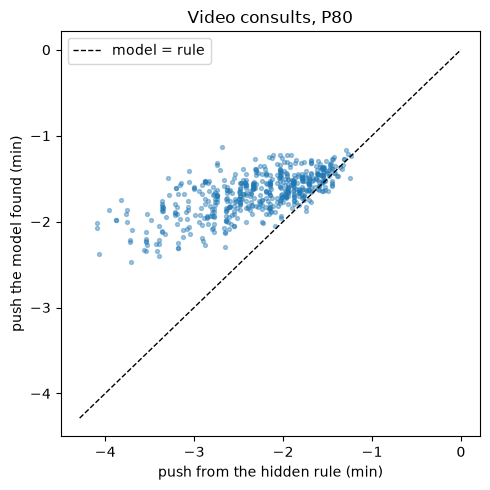

In [8]:
video = visits["teleconsult"].astype(bool).to_numpy()
model_push = P["teleconsult"].to_numpy()[video]
rule_push = ex.video_push_by_rule(visits["in_person_minutes"].to_numpy()[video], 0.8)
print(f"{video.sum()} video visits in Jul-Aug ({video.mean():.1%} of all visits)")
print(f"average push   model {model_push.mean():.2f} min   rule {rule_push.mean():.2f} min")
print(f"the example visit: model {P.loc[i, 'teleconsult']:.2f}, rule {ex.video_push_by_rule(visits.loc[i, 'in_person_minutes'], 0.8):.2f}")

plt.figure(figsize=(5, 5))
plt.scatter(rule_push, model_push, s=8, alpha=0.4)
lim = [min(rule_push.min(), model_push.min()) - 0.2, 0]
plt.plot(lim, lim, "k--", lw=1, label="model = rule")
plt.xlabel("push from the hidden rule (min)"); plt.ylabel("push the model found (min)")
plt.title("Video consults, P80"); plt.legend(); plt.tight_layout(); plt.show()

**Questions** (short answers, your own words)
1. General Medicine is one of the quickest departments, yet in section 2 `department` got only about **−0.06** while `doctor` got **−2.8**. Where did the department's credit go?
2. In section 3, `teleconsult` is a tiny push on average, yet for the visit in section 2 it was about **−1.5**. How can both be true?
3. The visit in section 2 actually took **4.2 minutes**, against a P80 of 6.6. Was the model wrong for this visit?
4. In the scatter, short video visits sit on the dashed line, but for long ones the model's push is smaller than the rule's. Look at who gets video consults in `simulate.py` (which visit types?). Why might the model have learned video as "about 1.5–2 minutes off" instead of "20% off"?

*Answers:*
1. Every doctor works in exactly one department, so knowing the doctor already tells the model the department. The doctor column therefore carries the department’s information plus that doctor’s own pace. The trees split on doctor and did not need to use department separately, so the doctor received about −2.8 while department received only −0.06. SHAP values explain how the model distributed credit; they are not independent causal effects.
2. Video visits are relatively uncommon, so their average contribution is small. For this particular follow-up visit, the model identified video as a strong shortening signal, producing a push of roughly −1.5 minutes. A feature can therefore have a small average effect while having a large effect for selected rows
3. No—the model was not wrong for this visit. A P80 prediction of 6.6 minutes means the model expects about 80% of comparable visits to finish within 6.6 minutes. The actual duration, 4.2 minutes, is below that threshold, so this visit was successfully covered by the prediction. It was simply shorter than the model’s upper-quantile estimate.
4. In simulate.py, video is assigned only to follow-up visits, never new visits, and only for non-Paediatrics departments, with roughly a 10% chance. Follow-ups are short, usually about 6–12 minutes in person, so on a 7–8 minute visit a 20% reduction is already about 1.5 minutes. In the training data, “20% off” and “about 1.5 minutes off” therefore produce nearly the same numbers, so the model cannot clearly tell the rules apart. It learns a roughly fixed −1.5 to −2 minute adjustment and only shows the mismatch on the rare long video visits it hardly saw.